## 5.5. Distribuição do PIB: escala original x log

O PIB municipal é extremamente assimétrico (Brasília e as capitais concentram boa parte da riqueza). A transformação log10 aproxima a distribuição de uma forma simétrica, o que justifica usar variáveis em log e modelar o **crescimento** (razão entre anos) em vez do valor bruto.

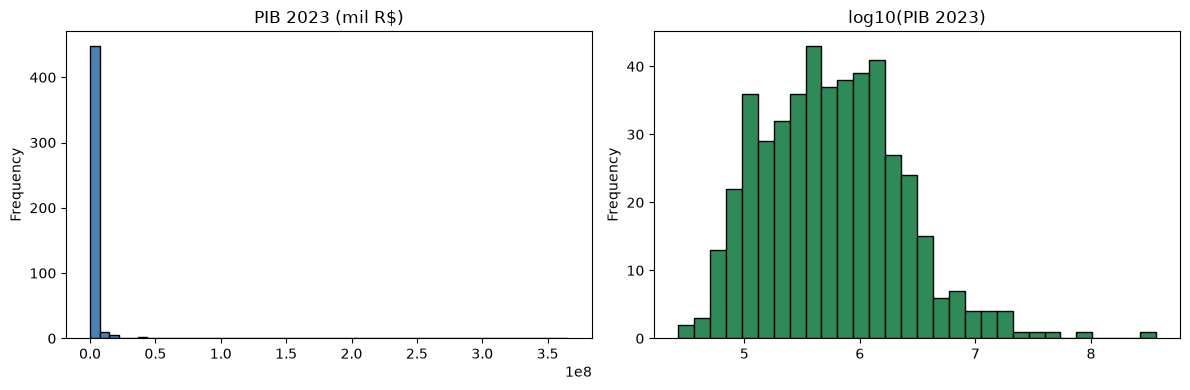

Assimetria (skew) do PIB: 19.2 | do log10(PIB): 0.57
Participação do DF no PIB do Centro-Oeste em 2023: 31.5%


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
du.pib.plot.hist(bins=50, ax=ax[0], color="steelblue", edgecolor="k", title="PIB 2023 (mil R$)")
du.log_pib.plot.hist(bins=30, ax=ax[1], color="seagreen", edgecolor="k", title="log10(PIB 2023)")
plt.tight_layout(); plt.show()
print(f"Assimetria (skew) do PIB: {du.pib.skew():.1f} | do log10(PIB): {du.log_pib.skew():.2f}")
print("Participação do DF no PIB do Centro-Oeste em 2023: %.1f%%" % (100 * du[du.uf == "DF"].pib.sum() / du.pib.sum()))

## 5.6. Crescimento anual do PIB: o efeito do ano

O crescimento é **nominal** (preços correntes), então inflação e ciclo das commodities deslocam todos os municípios juntos. Para capturar esse efeito, trazemos o PIB nominal do Brasil (SIDRA, tabela 6784), que o IBGE publica cerca de 2 anos antes do PIB municipal do mesmo ano.

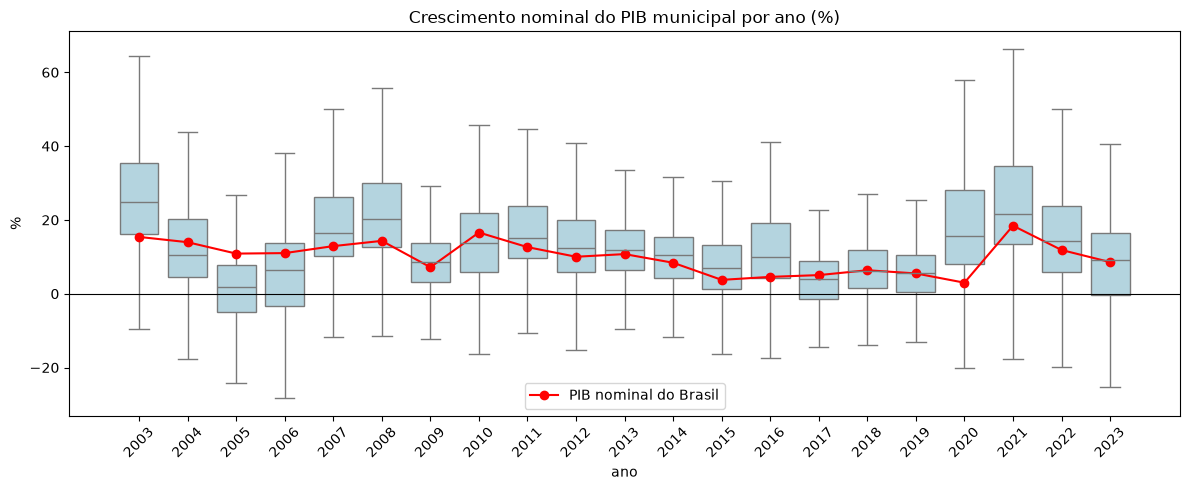

                       2003  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023
mediana_municipios_CO  24.8  10.6   1.9   6.4  16.5  20.2   8.5  13.7  15.0  12.3  11.8  10.4   6.9  10.1   4.1   6.2   5.5  15.6  21.7  14.2   9.1
brasil                 15.4  14.0  10.9  11.0  12.9  14.3   7.2  16.6  12.6  10.0  10.7   8.4   3.8   4.6   5.0   6.4   5.5   3.0  18.4  11.8   8.6
Correlação (Pearson) entre a mediana dos municípios e o Brasil: 0.63


In [12]:
# PIB nominal do Brasil (SIDRA 6784, variável 9808, R$ milhões)
br = pd.read_json("https://apisidra.ibge.gov.br/values/t/6784/n1/all/v/9808/p/all").iloc[1:]
pib_br = pd.Series(br.V.astype(float).values, index=br.D3C.astype(int).values, name="pib_brasil")
cresc_br = pib_br.pct_change() * 100

g = d.dropna(subset=["crescimento_pib_pct"])
anos_g = sorted(g.ano.unique())
plt.figure(figsize=(12, 5))
sns.boxplot(data=g, x="ano", y="crescimento_pib_pct", color="lightblue", showfliers=False)
plt.plot(range(len(anos_g)), cresc_br.reindex(anos_g).values, "r-o", label="PIB nominal do Brasil")
plt.axhline(0, color="k", lw=.8); plt.xticks(rotation=45); plt.legend()
plt.title("Crescimento nominal do PIB municipal por ano (%)"); plt.ylabel("%"); plt.tight_layout(); plt.show()

comp = pd.DataFrame({"mediana_municipios_CO": g.groupby("ano").crescimento_pib_pct.median(), "brasil": cresc_br.reindex(anos_g)})
print(comp.round(1).T.to_string())
print("Correlação (Pearson) entre a mediana dos municípios e o Brasil: %.2f" % comp.corr().iloc[0, 1])

## 5.7. Categorias de crescimento por ano (desbalanceamento)

In [13]:
tab = pd.crosstab(d.ano, d.categoria, normalize="index").mul(100).round(1)
display(tab.loc[2015:])
print("Distribuição geral (%):"); print(d.categoria.value_counts(normalize=True).mul(100).round(1).to_string())

categoria,Forte retração,Retração,Estabilidade,Crescimento moderado,Forte crescimento
ano,,,,,
2015,9.4,7.7,7.5,18.8,56.5
2016,3.9,7.1,4.1,14.6,70.4
2017,14.6,11.3,8.6,19.3,46.3
2018,8.4,6.6,7.3,20.6,57.2
2019,10.5,9.2,6.6,19.7,54.0
2020,3.0,3.0,2.1,9.2,82.7
2021,1.7,1.5,1.3,2.4,93.1
2022,7.5,4.9,1.7,8.1,77.7
2023,15.8,7.5,5.8,9.4,61.5


Distribuição geral (%):
categoria
Forte crescimento       71.3
Crescimento moderado    10.6
Forte retração           8.4
Retração                 5.7
Estabilidade             4.1


**Conclusões parciais da EDA**

- **PIB muito concentrado.** Assimetria de 19,2 na escala original e 0,57 em log10. Só o DF tem 31,5% do PIB da região em 2023, e os 5 maiores municípios somam 47%. Por isso as variáveis de escala entram em log e a regressão prevê o **crescimento**, não o valor bruto.
- **Forte efeito do ano.** A mediana do crescimento nominal vai de 1,9% (2005) a 24,8% (2003) e acompanha o PIB nominal do Brasil (correlação 0,63). Em 2020 e 2021 o Centro-Oeste cresceu muito acima do país, puxado pelo agro. Isso justifica incluir o crescimento do PIB do Brasil como variável.
- **Classes desbalanceadas.** "Forte crescimento" é 71% de todas as observações, porque o PIB é nominal e a inflação empurra quase todos para cima. "Estabilidade" é só 4%. Daí o uso de F1 macro e `class_weight="balanced"`.
- **2023 foi atípico.** 15,8% dos municípios ficaram em forte retração, a maior proporção da série recente, no mesmo ano em que o valor da produção agrícola da região caiu 9,4% (de R$ 303,9 bi para R$ 275,2 bi).

# 6. Pré-processamento para a modelagem

**Unidade de análise:** município × ano-alvo *t*. Para cada linha, as variáveis explicativas usam **apenas informação disponível antes da divulgação do PIB municipal de *t*** (o IBGE divulga o PIB municipal com ~2 anos de defasagem):

| Grupo | Variáveis | Por que é legítimo usar |
|---|---|---|
| Histórico do PIB | `log_pib_lag1`, `g_lag1`, `g_lag2`, `g_lag3`, `vol5`, `log_pibpc_lag1` | PIB até *t-1* já foi publicado |
| População de *t* | `log_pop`, `g_pop` | Estimativa publicada em agosto de *t* |
| Lavouras de *t* (PAM) | `pam_share`, `impacto_pam` | PAM de *t* sai em setembro de *t+1* |
| Macro | `g_pib_brasil` | Contas Nacionais de *t* saem em março de *t+1* |
| Estrutura setorial | `sh_agro`, `sh_industria`, `sh_servicos`, `sh_adm_publica` | Última composição conhecida (ano *t-1*, limitada a 2021) |
| Categórica | `uf` | Codificada com one-hot |

**Alvos:** regressão: `g_pib` = ln(PIB_t / PIB_t-1), convertido de volta para PIB com PIB_t-1 × exp(ĝ); classificação: `categoria` (faixas do enunciado aplicadas ao crescimento de *t*).

> A composição setorial **fixa de 2021** (seção 4) seria vazamento de informação para anos-alvo anteriores a 2021; por isso aqui usamos a composição do ano anterior ao alvo (e a de 2021 para 2022 em diante, já que o VAB de 2022 e 2023 não existe).

In [14]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (r2_score, mean_absolute_percentage_error, f1_score,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

CATS = list(df.categoria.cat.categories)          # mesmas faixas da seção 4
ANOS = range(2001, 2025)

# tabelas largas município x ano (inclui anos vazios, para os lags caírem no ano certo)
larga = lambda tab, col: (tab.pivot_table(index="cod_mun", columns="ano", values=col)
                             .reindex(index=mun.cod_mun, columns=ANOS))
P = larga(pib, "pib")                                                  # PIB 2002-2023
POP = larga(pop, "populacao").T.interpolate(limit_direction="both").T  # preenche 2007, 2010, 2022 e 2023
PAM = larga(pam, "pam_valor_producao").fillna(0)                       # sem registro = sem lavoura
SH = {s: larga(df, "%" + s) for s in setores}                          # participação setorial (até 2021)
LN = np.log(P)

def base_ano(t):
    b = pd.DataFrame(index=P.index); b["ano"] = t
    b["pib_lag1"] = P[t - 1]
    b["log_pib_lag1"] = np.log10(P[t - 1])
    for k in (1, 2, 3): b[f"g_lag{k}"] = LN[t - k] - LN[t - k - 1]             # crescimento (log) passado
    b["vol5"] = pd.concat([LN[t - k] - LN[t - k - 1] for k in range(1, 6)], axis=1).std(axis=1)
    b["log_pibpc_lag1"] = np.log10(P[t - 1] * 1000 / POP[t - 1])
    b["log_pop"], b["g_pop"] = np.log10(POP[t]), np.log(POP[t] / POP[t - 1])
    b["pam_share"] = PAM[t] / P[t - 1]                                        # peso da lavoura na economia
    b["impacto_pam"] = (PAM[t] - PAM[t - 1]) / P[t - 1]                       # variação da lavoura / PIB anterior
    b["g_pib_brasil"] = np.log(pib_br[t] / pib_br[t - 1])
    for s in setores: b["sh_" + s[4:]] = SH[s][min(t - 1, 2021)]
    b["g_pib"], b["pib"] = LN[t] - LN[t - 1], P[t]                          # alvos (vazios em 2024)
    return b.reset_index()

base = pd.concat([base_ano(t) for t in range(2007, 2025)]).merge(mun, on="cod_mun")
base = base[base.pib_lag1.notna()].reset_index(drop=True)      # sem PIB anterior não há o que prever
base["crescimento_pct"] = (np.exp(base.g_pib) - 1) * 100
base["categoria"] = pd.cut(base.crescimento_pct, [-np.inf, -5, -1, 1, 5, np.inf], include_lowest=True, labels=CATS)

NUM = ["log_pib_lag1", "g_lag1", "g_lag2", "g_lag3", "vol5", "log_pibpc_lag1", "log_pop", "g_pop",
       "pam_share", "impacto_pam", "g_pib_brasil", "sh_agro", "sh_industria", "sh_servicos", "sh_adm_publica"]

# checagens: chave única, lag coerente com o alvo do ano anterior, 2024 completo
assert not base.duplicated(["cod_mun", "ano"]).any()
chk = base.merge(base[["cod_mun", "ano", "g_pib"]].assign(ano=lambda x: x.ano + 1), on=["cod_mun", "ano"], suffixes=("", "_ant"))
assert np.allclose(chk.g_lag1, chk.g_pib_ant, equal_nan=True)
assert base[base.ano == 2024][["pib_lag1", "log_pop", "pam_share", "g_pib_brasil"]].notna().all().all()

base.to_csv("base_modelagem.csv", index=False)
print(base.shape, "| anos-alvo:", base.ano.min(), "a", base.ano.max(), "| linhas de 2024:", (base.ano == 2024).sum())
print("Ausentes nas variáveis explicativas (%):"); print((base[NUM].isna().mean() * 100).round(2)[lambda s: s > 0].to_string())

(8399, 24) | anos-alvo: 2007 a 2024 | linhas de 2024: 467
Ausentes nas variáveis explicativas (%):
g_lag1    0.01
g_lag2    0.06
g_lag3    0.11
vol5      0.06


## 6.1. Relação das variáveis explicativas com o crescimento do PIB

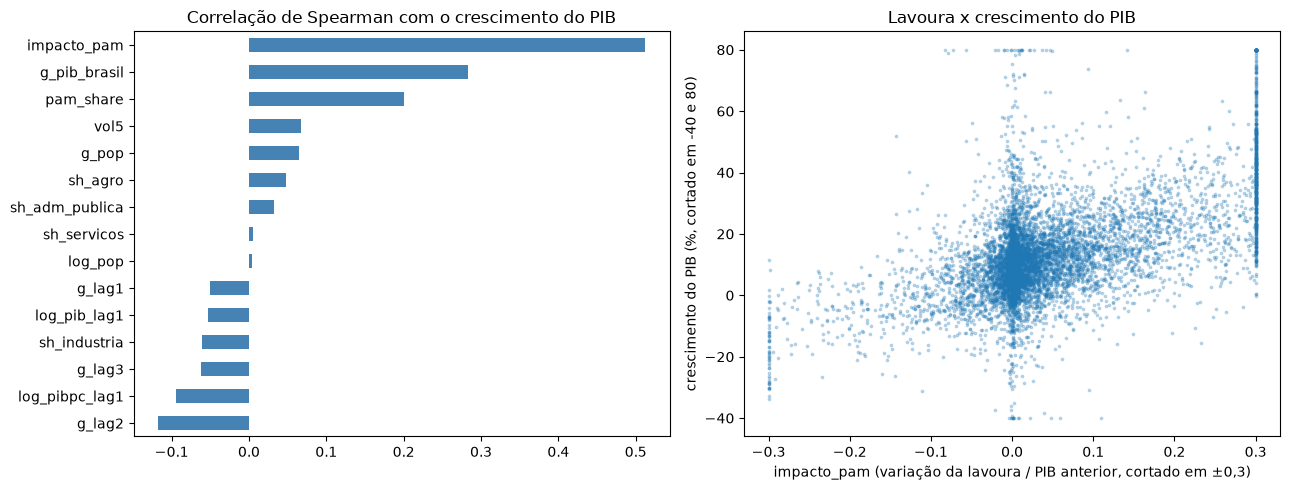

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
base[NUM + ["g_pib"]].corr("spearman")["g_pib"].drop("g_pib").sort_values().plot.barh(ax=ax[0], color="steelblue")
ax[0].set_title("Correlação de Spearman com o crescimento do PIB")
m = base.dropna(subset=["g_pib"])
ax[1].scatter(m.impacto_pam.clip(-.3, .3), m.crescimento_pct.clip(-40, 80), s=3, alpha=.25)
ax[1].set_xlabel("impacto_pam (variação da lavoura / PIB anterior, cortado em ±0,3)")
ax[1].set_ylabel("crescimento do PIB (%, cortado em -40 e 80)"); ax[1].set_title("Lavoura x crescimento do PIB")
plt.tight_layout(); plt.show()

## 6.2. Normalização, padronização, codificação e outliers

- **Normalização da escala:** PIB, população e PIB per capita entram em log10; o alvo é o crescimento em log. Isso reduz a assimetria vista em 5.5.
- **Padronização:** `StandardScaler` (média 0, desvio 1) nas variáveis numéricas dos modelos lineares (Ridge e Regressão Logística). Árvores não dependem de escala, então não recebem padronização.
- **Codificação de categóricas:** `uf` vira 4 colunas binárias (`OneHotEncoder`). A categoria de crescimento (alvo) é tratada como rótulo de classe.
- **Ausentes:** lags inexistentes (municípios instalados em 2005 e 2013) são imputados pela mediana do treino (`SimpleImputer`), dentro do pipeline, para não vazar informação do teste.
- **Outliers do alvo:** no treino da regressão, o crescimento é limitado aos percentis 0,5% e 99,5% do próprio treino (winsorização). Casos como Cachoeira Dourada (VAB industrial negativo em 2021) geram crescimentos de -83% em 2021 e +1.321% em 2022, que distorceriam os modelos.

In [16]:
def preproc(padronizar):
    num = [SimpleImputer(strategy="median")] + ([StandardScaler()] if padronizar else [])
    return ColumnTransformer([("num", make_pipeline(*num), NUM),
                              ("uf", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["uf"])])

def winsoriza(y):
    return y.clip(*y.quantile([.005, .995]))

ex = preproc(True).fit(base[base.ano <= 2022])
Xt = pd.DataFrame(ex.transform(base[base.ano <= 2022]), columns=[c.split("__")[1] for c in ex.get_feature_names_out()])
display(Xt.describe().T[["mean", "std", "min", "max"]].round(2))

,mean,std,min,max
log_pib_lag1,-0.00,1.00,-2.34,5.01
g_lag1,-0.00,1.00,-12.66,17.66
g_lag2,0.00,1.00,-11.79,17.87
g_lag3,0.00,1.00,-11.87,18.03
vol5,-0.00,1.00,-1.25,10.81
log_pibpc_lag1,0.00,1.00,-2.80,4.28
log_pop,0.00,1.00,-2.11,4.91
g_pop,0.00,1.00,-7.97,21.42
pam_share,-0.00,1.00,-0.78,9.03
impacto_pam,-0.00,1.00,-5.98,10.69


# 7. Modelagem e avaliação: treino até 2022, teste em 2023

- **Divisão treino/teste temporal:** treino com anos-alvo 2007 a 2022; teste com 2023 (dado oficial que os modelos nunca viram).
- **Validação e ajuste de hiperparâmetros:** validação cruzada temporal com janela expansível (`GridSearchCV`): cada fold treina com os anos anteriores a *v* e valida em *v*, para *v* = 2019, 2020, 2021 e 2022. Nunca se usa o futuro para prever o passado.
- **Regressão:** Ridge (linear regularizado), Random Forest e HistGradientBoosting, comparados a dois *baselines*: repetir o PIB de 2022 e aplicar ao PIB de 2022 o crescimento do Brasil. O modelo escolhido é o de menor soma de rankings nas duas métricas pedidas (MAPE e R²).
- **Classificação:** Regressão Logística, Random Forest e HistGradientBoosting (com `class_weight="balanced"`, pois as classes são desbalanceadas), comparados ao *baseline* de repetir a categoria de 2022 e à categoria obtida a partir da melhor regressão. Vence a abordagem de maior F1 macro.

In [17]:
treino = base[(base.ano <= 2022) & base.g_pib.notna()].reset_index(drop=True)
teste = base[(base.ano == 2023) & base.g_pib.notna()].reset_index(drop=True)
folds = lambda dados: [(np.where(dados.ano < v)[0], np.where(dados.ano == v)[0]) for v in (2019, 2020, 2021, 2022)]
print(f"Treino: {len(treino)} linhas ({treino.ano.min()}-{treino.ano.max()}) | Teste 2023: {len(teste)} municípios")

Treino: 7465 linhas (2007-2022) | Teste 2023: 467 municípios


## 7.1. Regressão

In [18]:
REG = {
    "Ridge": (make_pipeline(preproc(True), Ridge()), {"ridge__alpha": [0.1, 1, 10, 100]}),
    "Random Forest": (make_pipeline(preproc(False), RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)),
                      {"randomforestregressor__min_samples_leaf": [5, 20], "randomforestregressor__max_features": [1.0, 0.5]}),
    "HistGradientBoosting": (make_pipeline(preproc(False), HistGradientBoostingRegressor(max_iter=300, random_state=42)),
                             {"histgradientboostingregressor__learning_rate": [0.03, 0.1],
                              "histgradientboostingregressor__min_samples_leaf": [20, 50]}),
}

def avalia_reg(nome, g_prev, dados=teste):
    pib_prev = dados.pib_lag1 * np.exp(g_prev)
    return {"modelo": nome, "R2": r2_score(dados.pib, pib_prev),
            "R2 log(PIB)": r2_score(np.log(dados.pib), np.log(pib_prev)),
            "R2 crescimento": r2_score(dados.g_pib, g_prev),
            "MAPE (%)": 100 * mean_absolute_percentage_error(dados.pib, pib_prev)}

busca_reg, prev_reg = {}, {}
linhas = [avalia_reg("Baseline: PIB 2022", np.zeros(len(teste))),
          avalia_reg("Baseline: PIB 2022 x cresc. Brasil", teste.g_pib_brasil)]
for nome, (modelo, grade) in REG.items():
    busca_reg[nome] = GridSearchCV(modelo, grade, cv=folds(treino), scoring="neg_mean_absolute_error").fit(treino, winsoriza(treino.g_pib))
    prev_reg[nome] = busca_reg[nome].predict(teste)
    linhas.append(avalia_reg(nome, prev_reg[nome]) | {"melhores parâmetros": {k.split("__")[1]: v for k, v in busca_reg[nome].best_params_.items()},
                                                    "MAE validação (log)": -busca_reg[nome].best_score_})
res_reg = pd.DataFrame(linhas).set_index("modelo")
display(res_reg.round(4))
# escolha pelas duas métricas pedidas: soma dos rankings em MAPE (menor melhor) e R2 (maior melhor)
rank = res_reg.loc[list(REG), "MAPE (%)"].rank() + res_reg.loc[list(REG), "R2"].rank(ascending=False)
MELHOR_REG = rank.idxmin()
print("Soma dos rankings (MAPE + R2):", rank.to_dict(), "| melhor regressor:", MELHOR_REG)

,R2,R2 log(PIB),R2 crescimento,MAPE (%),melhores parâmetros,MAE validação (log)
modelo,,,,,,
Baseline: PIB 2022,0.9895,0.9855,-0.3186,12.0946,NaN,NaN
Baseline: PIB 2022 x cresc. Brasil,0.9991,0.9890,-0.0000,10.7840,NaN,NaN
Ridge,0.9951,0.9938,0.4322,7.6674,{'alpha': 100},0.0820
Random Forest,0.9997,0.9935,0.4048,7.7264,"{'max_features': 1.0, 'min_samples_leaf': 5}",0.0758
HistGradientBoosting,0.9986,0.9930,0.3606,8.0878,"{'learning_rate': 0.03, 'min_samples_leaf': 20}",0.0754


Soma dos rankings (MAPE + R2): {'Ridge': 4.0, 'Random Forest': 3.0, 'HistGradientBoosting': 5.0} | melhor regressor: Random Forest


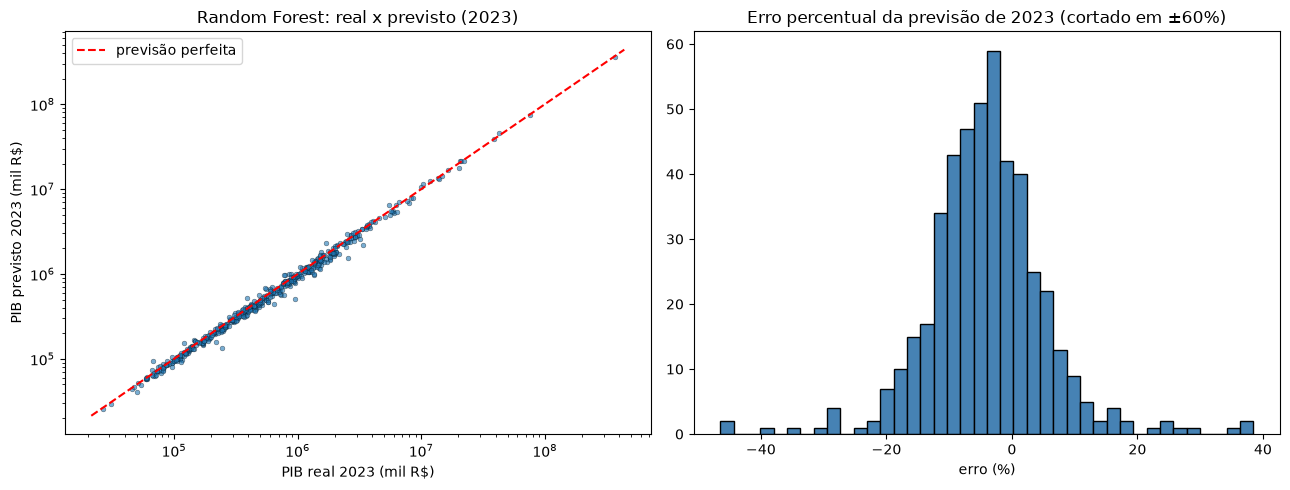

Erro percentual absoluto por UF (mediana, %):
uf
DF    0.8
GO    4.5
MS    6.9
MT    8.6
Municípios com erro absoluto <= 5%: 43% | <= 10%: 73%


In [19]:
pib_prev23 = teste.pib_lag1 * np.exp(prev_reg[MELHOR_REG])
erro_pct = 100 * (pib_prev23 - teste.pib) / teste.pib
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(teste.pib, pib_prev23, s=12, alpha=.6, edgecolors="k", linewidths=.3)
lim = [teste.pib.min() * .8, teste.pib.max() * 1.2]
ax[0].plot(lim, lim, "r--", label="previsão perfeita"); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("PIB real 2023 (mil R$)"); ax[0].set_ylabel("PIB previsto 2023 (mil R$)")
ax[0].set_title(f"{MELHOR_REG}: real x previsto (2023)"); ax[0].legend()
ax[1].hist(erro_pct.clip(-60, 60), bins=40, color="steelblue", edgecolor="k")
ax[1].set_title("Erro percentual da previsão de 2023 (cortado em ±60%)"); ax[1].set_xlabel("erro (%)")
plt.tight_layout(); plt.show()
print("Erro percentual absoluto por UF (mediana, %):")
print(erro_pct.abs().groupby(teste.uf).median().round(1).to_string())
print(f"Municípios com erro absoluto <= 5%: {(erro_pct.abs() <= 5).mean():.0%} | <= 10%: {(erro_pct.abs() <= 10).mean():.0%}")

## 7.2. Classificação

In [20]:
CLF = {
    "Regressão Logística": (make_pipeline(preproc(True), LogisticRegression(max_iter=3000, class_weight="balanced")),
                            {"logisticregression__C": [0.1, 1, 10]}),
    "Random Forest": (make_pipeline(preproc(False), RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42)),
                      {"randomforestclassifier__min_samples_leaf": [3, 10], "randomforestclassifier__max_features": ["sqrt", 0.5]}),
    "HistGradientBoosting": (make_pipeline(preproc(False), HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=42)),
                             {"histgradientboostingclassifier__learning_rate": [0.03, 0.1],
                              "histgradientboostingclassifier__min_samples_leaf": [20, 50]}),
}
cat_de = lambda g: pd.cut((np.exp(g) - 1) * 100, [-np.inf, -5, -1, 1, 5, np.inf], include_lowest=True, labels=CATS).astype(str)
y_teste = teste.categoria.astype(str)

def avalia_clf(nome, prev):
    return {"modelo": nome, "F1 macro": f1_score(y_teste, prev, average="macro"),
            "F1 ponderado": f1_score(y_teste, prev, average="weighted"), "acurácia": (y_teste == np.asarray(prev)).mean()}

busca_clf, prev_clf = {}, {"Baseline: categoria de 2022": cat_de(teste.g_lag1),
                           f"Via regressão ({MELHOR_REG})": cat_de(prev_reg[MELHOR_REG])}
for nome, (modelo, grade) in CLF.items():
    busca_clf[nome] = GridSearchCV(modelo, grade, cv=folds(treino), scoring="f1_macro").fit(treino, treino.categoria.astype(str))
    prev_clf[nome] = busca_clf[nome].predict(teste)
res_clf = pd.DataFrame([avalia_clf(n, p) for n, p in prev_clf.items()]).set_index("modelo")
res_clf["melhores parâmetros"] = pd.Series({n: {k.split("__")[1]: v for k, v in b.best_params_.items()} for n, b in busca_clf.items()})
display(res_clf.round(3))
MELHOR_CLF = res_clf.drop(index="Baseline: categoria de 2022")["F1 macro"].idxmax()
print("Melhor abordagem de classificação no teste de 2023 (maior F1 macro):", MELHOR_CLF)
print("Distribuição real de 2023:", y_teste.value_counts().to_dict())

,F1 macro,F1 ponderado,acurácia,melhores parâmetros
modelo,,,,
Baseline: categoria de 2022,0.154,0.411,0.460,NaN
Via regressão (Random Forest),0.377,0.629,0.602,NaN
Regressão Logística,0.225,0.345,0.332,{'C': 1}
Random Forest,0.274,0.528,0.518,"{'max_features': 0.5, 'min_samples_leaf': 3}"
HistGradientBoosting,0.267,0.511,0.493,"{'learning_rate': 0.03, 'min_samples_leaf': 20}"


Melhor abordagem de classificação no teste de 2023 (maior F1 macro): Via regressão (Random Forest)
Distribuição real de 2023: {'Forte crescimento': 287, 'Forte retração': 74, 'Crescimento moderado': 44, 'Retração': 35, 'Estabilidade': 27}


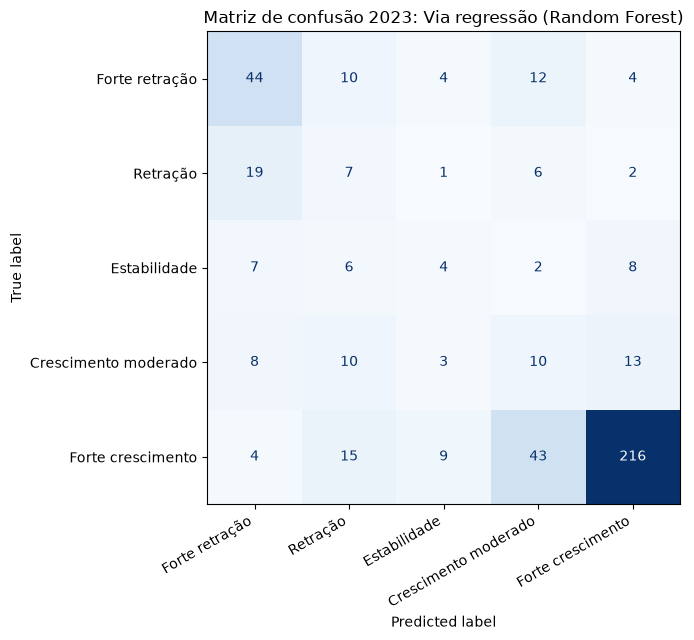

                      precision    recall  f1-score   support

      Forte retração       0.54      0.59      0.56        74
            Retração       0.15      0.20      0.17        35
        Estabilidade       0.19      0.15      0.17        27
Crescimento moderado       0.14      0.23      0.17        44
   Forte crescimento       0.89      0.75      0.82       287

            accuracy                           0.60       467
           macro avg       0.38      0.38      0.38       467
        weighted avg       0.67      0.60      0.63       467



In [21]:
fig, ax = plt.subplots(figsize=(8, 6.5))
ConfusionMatrixDisplay.from_predictions(y_teste, prev_clf[MELHOR_CLF], labels=CATS, cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Matriz de confusão 2023: {MELHOR_CLF}"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
print(classification_report(y_teste, prev_clf[MELHOR_CLF], labels=CATS, zero_division=0))

## 7.3. Importância das variáveis (permutação no teste de 2023)

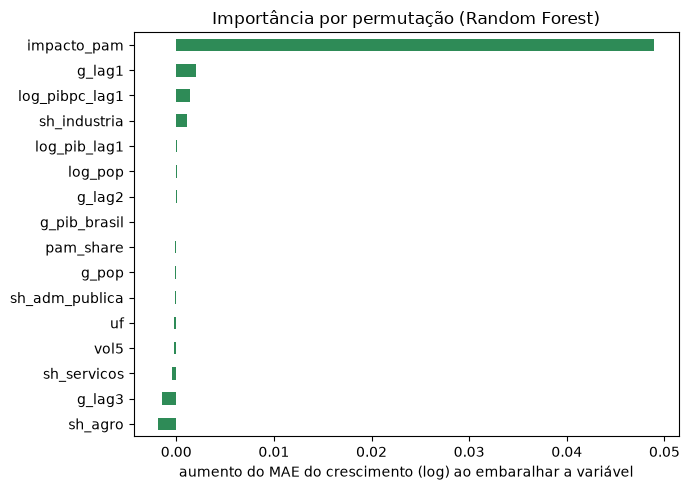

In [22]:
imp = permutation_importance(busca_reg[MELHOR_REG].best_estimator_, teste, teste.g_pib, scoring="neg_mean_absolute_error",
                             n_repeats=10, random_state=42)
imp = pd.Series(imp.importances_mean, index=teste.columns).loc[NUM + ["uf"]].sort_values()
imp.plot.barh(figsize=(7, 5), color="seagreen", title=f"Importância por permutação ({MELHOR_REG})")
plt.xlabel("aumento do MAE do crescimento (log) ao embaralhar a variável"); plt.tight_layout(); plt.show()

In [23]:
# previsões de 2023 por município (validação), para consulta
val23 = teste[["cod_mun", "municipio", "uf", "pib_lag1", "pib", "crescimento_pct", "categoria"]].rename(
    columns={"pib_lag1": "pib_2022", "pib": "pib_2023_real", "crescimento_pct": "crescimento_2023_real_pct", "categoria": "categoria_2023_real"})
val23["pib_2023_previsto"] = pib_prev23.round(0)
val23["erro_pct"] = erro_pct.round(2)
val23["categoria_2023_prevista"] = np.asarray(prev_clf[MELHOR_CLF])
val23.to_csv("previsoes_2023_validacao.csv", index=False)

**Conclusões parciais da modelagem**

- **Todos os modelos superam os baselines.** MAPE de 7,7% a 8,1%, contra 12,1% de repetir o PIB de 2022 e 10,8% de aplicar o crescimento do Brasil.
- **R² em nível engana.** Fica acima de 0,99 até no baseline, porque é dominado pela escala (Brasília vale 31% da região). O R² do crescimento separa melhor: de 0,36 a 0,43 nos modelos, contra valores negativos ou zero nos baselines.
- **Random Forest escolhido.** Tem o melhor R² (0,9997) e MAPE de 7,73%, a 0,06 ponto do Ridge (7,67%). A diferença decisiva está nos grandes municípios: o Ridge previu +3,4% para Brasília, que cresceu 11,2%; o Random Forest errou o PIB de Brasília em só 0,8%. Na validação cruzada temporal (2019 a 2022), Random Forest e HistGradientBoosting também tiveram erro menor que o Ridge.
- **Tamanho do erro.** 43% dos municípios com erro de até 5% e 73% com erro de até 10%. A mediana do erro absoluto é de 0,8% no DF, 4,5% em GO, 6,9% em MS e 8,6% em MT: quanto mais agrícola a economia, mais difícil prever.
- **Viés.** 71% dos municípios foram subestimados (erro mediano de -4,1%): 2023 cresceu acima do que o padrão histórico indicava.
- **Classificação.** Derivar a categoria do crescimento previsto pela regressão (F1 macro 0,377; acurácia 60%) supera os classificadores diretos (F1 macro de 0,225 a 0,274) e o baseline (0,154). As categorias são cortes de uma variável contínua: o classificador direto perde a ordem entre elas e sofre com as classes raras. As faixas extremas são bem acertadas (F1 de 0,82 em forte crescimento e 0,56 em forte retração). As três centrais, com largura de 2 a 4 pontos, ficam perto de 0,17: um erro de poucos pontos no crescimento já muda a faixa.
- **O que mais pesa.** `impacto_pam` (variação da lavoura em relação ao PIB anterior) domina a importância no teste de 2023. `g_pib_brasil` aparece com importância zero porque é constante dentro de um mesmo ano, e embaralhá-la num único ano não muda nada. O papel dela é ajustar o nível geral entre anos, e isso só aparece comparando anos diferentes.

# 8. Previsões para 2024

Com os modelos escolhidos no teste de 2023, retreinamos com **todos os anos-alvo até 2023** (mesmos hiperparâmetros) e prevemos 2024 usando o PIB de 2023, a população e a PAM de 2024 e o PIB do Brasil de 2024.

In [24]:
completo = base[base.g_pib.notna()].reset_index(drop=True)
alvo24 = base[base.ano == 2024].reset_index(drop=True)

reg_final = clone(busca_reg[MELHOR_REG].best_estimator_).fit(completo, winsoriza(completo.g_pib))
g24 = reg_final.predict(alvo24)

if MELHOR_CLF.startswith("Via regressão"):
    cat24 = cat_de(g24)                      # categoria coerente com o PIB previsto
else:
    cat24 = clone(busca_clf[MELHOR_CLF].best_estimator_).fit(completo, completo.categoria.astype(str)).predict(alvo24)

prev24 = pd.DataFrame({"cod_mun": alvo24.cod_mun, "municipio": alvo24.municipio, "uf": alvo24.uf,
                       "pib_2023": alvo24.pib_lag1, "pib_2024_previsto": (alvo24.pib_lag1 * np.exp(g24)).round(0),
                       "crescimento_2024_previsto_pct": ((np.exp(g24) - 1) * 100).round(2),
                       "categoria_2024_prevista": cat24})
# municípios da região sem PIB em 2023 (instalados depois) entram no arquivo com a explicação
faltam = mun[~mun.cod_mun.isin(prev24.cod_mun)]
prev24 = pd.concat([prev24, faltam.assign(observacao="Instalado em 2025: não existe PIB 2023 nem 2024 (território contado em Sorriso e Nova Ubiratã)")])
prev24 = prev24.sort_values(["uf", "municipio"]).reset_index(drop=True)
assert len(prev24) == len(mun) and prev24.cod_mun.is_unique
prev24.to_csv("previsoes_2024.csv", index=False)
print(f"{prev24.pib_2024_previsto.notna().sum()} municípios previstos + {len(faltam)} sem histórico: {faltam.municipio.tolist()}")
display(prev24.head())

467 municípios previstos + 1 sem histórico: ['Boa Esperança do Norte']


,cod_mun,municipio,uf,pib_2023,pib_2024_previsto,crescimento_2024_previsto_pct,categoria_2024_prevista,observacao
0,5300108,Brasília,DF,365669108.0,398765577.0,9.05,Forte crescimento,NaN
1,5200050,Abadia de Goiás,GO,477983.0,526029.0,10.05,Forte crescimento,NaN
2,5200100,Abadiânia,GO,633025.0,702080.0,10.91,Forte crescimento,NaN
3,5200134,Acreúna,GO,1188179.0,1327325.0,11.71,Forte crescimento,NaN
4,5200159,Adelândia,GO,59486.0,65513.0,10.13,Forte crescimento,NaN


PIB agregado (R$ bilhões):


,pib_2023,pib_2024_previsto,crescimento_%
uf,,,
DF,365.67,398.77,9.05
GO,336.75,361.83,7.45
MS,184.40,190.04,3.06
MT,273.01,278.44,1.99
Centro-Oeste,1159.83,1229.08,5.97


Crescimento previsto por município (%):
count    467.00
mean       2.96
std        8.80
min      -23.84
25%       -3.81
50%        4.68
75%       10.23
max       46.80


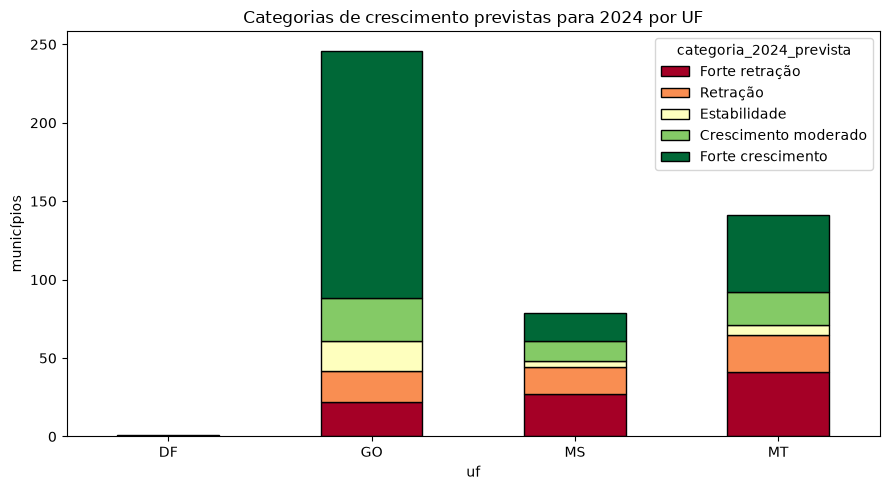

categoria_2024_prevista
Forte retração           90
Retração                 61
Estabilidade             29
Crescimento moderado     61
Forte crescimento       226


In [25]:
p = prev24.dropna(subset=["pib_2024_previsto"])
uf24 = p.groupby("uf")[["pib_2023", "pib_2024_previsto"]].sum() / 1e6
uf24.loc["Centro-Oeste"] = uf24.sum()
uf24["crescimento_%"] = 100 * (uf24.pib_2024_previsto / uf24.pib_2023 - 1)
print("PIB agregado (R$ bilhões):"); display(uf24.round(2))
print("Crescimento previsto por município (%):"); print(p.crescimento_2024_previsto_pct.describe().round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
(pd.crosstab(p.uf, p.categoria_2024_prevista).reindex(columns=CATS, fill_value=0)
   .plot.bar(stacked=True, ax=ax, colormap="RdYlGn", edgecolor="k"))
ax.set_title("Categorias de crescimento previstas para 2024 por UF"); ax.set_ylabel("municípios"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
print(p.categoria_2024_prevista.value_counts().reindex(CATS, fill_value=0).to_string())

In [26]:
cols = ["municipio", "uf", "pib_2023", "pib_2024_previsto", "crescimento_2024_previsto_pct", "categoria_2024_prevista"]
print("10 maiores PIBs previstos para 2024:"); display(p.nlargest(10, "pib_2024_previsto")[cols])
print("Maiores quedas previstas:"); display(p.nsmallest(5, "crescimento_2024_previsto_pct")[cols])
print("Maiores altas previstas:"); display(p.nlargest(5, "crescimento_2024_previsto_pct")[cols])

10 maiores PIBs previstos para 2024:


,municipio,uf,pib_2023,pib_2024_previsto,crescimento_2024_previsto_pct,categoria_2024_prevista
0,Brasília,DF,365669108.0,398765577.0,9.05,Forte crescimento
95,Goiânia,GO,75780846.0,84546008.0,11.57,Forte crescimento
265,Campo Grande,MS,42269768.0,47045791.0,11.30,Forte crescimento
362,Cuiabá,MT,39050753.0,43836945.0,12.26,Forte crescimento
16,Aparecida de Goiânia,GO,20888937.0,23484227.0,12.42,Forte crescimento
195,Rio Verde,GO,22310032.0,23045287.0,3.30,Crescimento moderado
15,Anápolis,GO,20432109.0,22493874.0,10.09,Forte crescimento
277,Dourados,MS,20257953.0,21189805.0,4.60,Crescimento moderado
435,Rondonópolis,MT,16568250.0,18127101.0,9.41,Forte crescimento
323,Três Lagoas,MS,14761816.0,15990450.0,8.32,Forte crescimento


Maiores quedas previstas:


,municipio,uf,pib_2023,pib_2024_previsto,crescimento_2024_previsto_pct,categoria_2024_prevista
233,Turvânia,GO,359274.0,273629.0,-23.84,Forte retração
418,Planalto da Serra,MT,296060.0,232740.0,-21.39,Forte retração
174,Panamá,GO,207977.0,163631.0,-21.32,Forte retração
394,Nortelândia,MT,399399.0,318841.0,-20.17,Forte retração
400,Nova Lacerda,MT,486837.0,394181.0,-19.03,Forte retração


Maiores altas previstas:


,municipio,uf,pib_2023,pib_2024_previsto,crescimento_2024_previsto_pct,categoria_2024_prevista
18,Aporé,GO,518582.0,761260.0,46.80,Forte crescimento
190,Professor Jamil,GO,86823.0,110851.0,27.67,Forte crescimento
88,Gameleira de Goiás,GO,244382.0,305009.0,24.81,Forte crescimento
42,Cachoeira de Goiás,GO,45522.0,55914.0,22.83,Forte crescimento
133,Mairipotaba,GO,101348.0,121906.0,20.28,Forte crescimento


**Conclusões parciais das previsões de 2024**

- **PIB previsto do Centro-Oeste:** R$ 1.229 bi em 2024 (+6,0% sobre 2023). Por UF: DF +9,1%, GO +7,5%, MS +3,1% e MT +2,0%.
- **Categorias (467 municípios):** 226 em forte crescimento, 61 em crescimento moderado, 29 em estabilidade, 61 em retração e 90 em forte retração.
- **Retrações concentradas no agro.** MS (44 de 79 municípios em retração ou forte retração) e MT (65 de 141) são justamente onde o valor da produção das lavouras mais caiu em 2024: -30,8% e -21,3%, contra -11,7% em GO. Em GO, 158 de 246 municípios ficam em forte crescimento.
- **Boa Esperança do Norte (MT)** foi instalado em 2025. Não existe PIB dele em 2023 nem em 2024 (o território era contado em Sorriso e Nova Ubiratã), então aparece no arquivo sem previsão e com a explicação.
- **Cuidados.** Em 2023 o modelo subestimou a maioria dos municípios (erro mediano de -4,1%), então o PIB de 2024 pode estar um pouco subestimado. As categorias centrais (retração, estabilidade e crescimento moderado) são as menos confiáveis.